# code_116 · Messages, aggregation and graph convolution choices

**Book:** section 23.2. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_23_GUIDE.md), [run evidence](../CHAPTER_23_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_116).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2516;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2516


<a id="message-contract"></a>
 ## A message has a source, destination and edge meaning
 First trace two layers on a five-member chain with observed load/material features and edge stiffness/length ratios. The declared message multiplies a transformed source feature by that edge ratio; the update adds a transformed own feature and applies ReLU. Check dense and indexed aggregation, exact two-hop support, node permutation equivariance, whole-graph pooling invariance and disconnected mini-batching. Then fit separate two-layer GCN, mean-GraphSAGE and GIN-style references on sixty independent twelve-node building graphs (40/10/10). Inputs and known connections are admitted; labels are a generated own/one-hop/two-hop response. These original Torch implementations expose operator equations, not full paper benchmarks or execution of PyTorch Geometric. Each gets two rates, 300 updates and its own development checkpoint.


,kind,development_MSE,final_MSE,selected_rate,best_step,parameters
0,GCN,0.081875,0.060759,0.005,120,353
1,Mean SAGE,0.001963,0.002514,0.010,300,657
2,GIN-style,0.079025,0.058829,0.010,140,899


,values,mean,sum,square_sum
0,"[1.0, 3.0]",2.0,4.0,10.0
1,[2.0],2.0,2.0,4.0
2,"[0.0, 4.0]",2.0,4.0,16.0


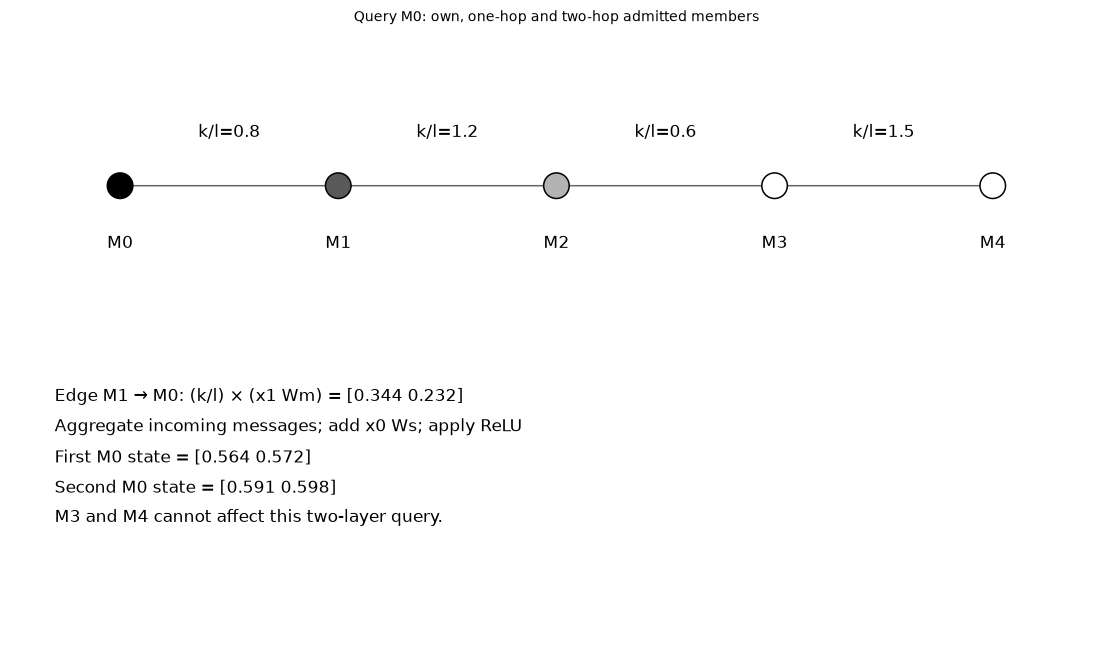

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
from matplotlib.patches import FancyArrowPatch
fixture=torch.tensor([[.2,.8],[1.,.3],[.4,.7],[1.2,.5],[.9,.1]],requires_grad=True);pairs=torch.tensor([[0,1],[1,2],[2,3],[3,4]]);ratios=torch.tensor([.8,1.2,.6,1.5]);source=torch.cat([pairs[:,0],pairs[:,1]]);destination=torch.cat([pairs[:,1],pairs[:,0]]);weight=torch.cat([ratios,ratios]);adj=torch.zeros(5,5);adj[destination,source]=weight
wm=torch.tensor([[.4,.2],[.1,.3]]);ws=torch.tensor([[.3,.1],[.2,.4]])
def message_layer(x,a):return torch.relu(x@ws+a@(x@wm))
messages=weight[:,None]*(fixture[source]@wm);summed=torch.zeros(5,2);summed.index_add_(0,destination,messages);torch.testing.assert_close(summed,adj@(fixture@wm));first=message_layer(fixture,adj);second=message_layer(first,adj);derivative=torch.autograd.grad(second[0].sum(),fixture,retain_graph=True)[0];assert torch.max(torch.abs(derivative[3:]))==0 and torch.linalg.vector_norm(derivative[2])>0
permutation=torch.tensor([3,0,4,1,2]);permuted=message_layer(message_layer(fixture[permutation],adj[permutation][:,permutation]),adj[permutation][:,permutation]);torch.testing.assert_close(permuted,second[permutation]);torch.testing.assert_close(permuted.mean(0),second.mean(0));torch.testing.assert_close(permuted.sum(0),second.sum(0))
joined=message_layer(message_layer(torch.cat([fixture,fixture]),torch.block_diag(adj,adj)),torch.block_diag(adj,adj));torch.testing.assert_close(joined[:5],second);torch.testing.assert_close(joined[5:],second)
trace={'edge_1_to_0_message':messages[(source==1)&(destination==0)].detach().numpy().ravel().tolist(),'node_0_first':first[0].detach().numpy().tolist(),'node_0_second':second[0].detach().numpy().tolist(),'node_0_two_layer_input_derivative':derivative.detach().numpy().tolist()}
B,N,F=60,12,3;raw=rng.normal(size=(B,N,F));a=np.zeros((B,N,N))
for b in range(B):
    for i in range(N-1):a[b,i,i+1]=a[b,i+1,i]=1
    for i in range(N):
        for j in range(i+2,N):
            if rng.random()<.08:a[b,i,j]=a[b,j,i]=1
p=a/a.sum(-1,keepdims=True);target=.4*raw[:,:,0]+.7*(p@raw)[:,:,0]-.3*(p@p@raw)[:,:,1]+rng.normal(0,.03,(B,N));scaler=StandardScaler().fit(raw[:40].reshape(-1,F));x=torch.tensor(scaler.transform(raw.reshape(-1,F)).reshape(B,N,F));y=torch.tensor(target);a=torch.tensor(a);p=torch.tensor(p);self_a=a+torch.eye(N);degree=self_a.sum(-1);gcn=self_a/torch.sqrt(degree[:,:,None]*degree[:,None,:])
class GraphLayer(nn.Module):
    def __init__(self,kind,incoming,outgoing):
        super().__init__();self.kind=kind
        if kind=='GCN':self.linear=nn.Linear(incoming,outgoing)
        elif kind=='Mean SAGE':self.own=nn.Linear(incoming,outgoing);self.neighbor=nn.Linear(incoming,outgoing,bias=False)
        else:self.epsilon=nn.Parameter(torch.tensor(0.));self.mlp=nn.Sequential(nn.Linear(incoming,outgoing),nn.ReLU(),nn.Linear(outgoing,outgoing))
    def forward(self,h):
        if self.kind=='GCN':return self.linear(gcn@h)
        if self.kind=='Mean SAGE':return self.own(h)+self.neighbor(p@h)
        return self.mlp((1+self.epsilon)*h+a@h)
class GraphModel(nn.Module):
    def __init__(self,kind):super().__init__();self.first=GraphLayer(kind,3,16);self.second=GraphLayer(kind,16,16);self.head=nn.Linear(16,1)
    def forward(self,h):return self.head(torch.relu(self.second(torch.relu(self.first(h))))).squeeze(-1)
rows=[];candidates=[]
for kind in ['GCN','Mean SAGE','GIN-style']:
    best_family=np.inf
    for rate in [.005,.01]:
        torch.manual_seed(SEED);model=GraphModel(kind);opt=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.001);best=np.inf
        for step in range(1,301):
            opt.zero_grad();pred=model(x);loss=torch.mean((pred[:40]-y[:40])**2);loss.backward();opt.step()
            if step%10==0:
                with torch.no_grad():score=float(torch.mean((model(x)[40:50]-y[40:50])**2))
                if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
        candidates.append({'kind':kind,'rate':rate,'development_MSE':best,'best_step':best_step})
        if best<best_family:best_family=best;chosen=(rate,best_step,state)
    rate,best_step,state=chosen;model.load_state_dict(state)
    with torch.no_grad():final=float(torch.mean((model(x)[50:]-y[50:])**2))
    rows.append({'kind':kind,'development_MSE':best_family,'final_MSE':final,'selected_rate':rate,'best_step':best_step,'parameters':sum(t.numel() for t in model.parameters())})
multisets=[np.array([1.,3.]),np.array([2.]),np.array([0.,4.])];collision=[{'values':v.tolist(),'mean':float(v.mean()),'sum':float(v.sum()),'square_sum':float(np.sum(v**2))} for v in multisets];assert collision[0]['mean']==collision[1]['mean'] and collision[0]['sum']!=collision[1]['sum'];assert collision[0]['sum']==collision[2]['sum'] and collision[0]['square_sum']!=collision[2]['square_sum']
RESULTS.update(comparisons=rows,candidates=candidates,split_graphs=[40,10,10],nodes_per_graph=12,manual_trace=trace,two_hop_outside_derivative_max=float(torch.max(torch.abs(derivative[3:]))),permutation_max_error=float(torch.max(torch.abs(permuted-second[permutation])).detach()),pooling_mean_max_error=float(torch.max(torch.abs(permuted.mean(0)-second.mean(0))).detach()),multiset_collisions=collision,disconnected_batch_verified=True);display(pd.DataFrame(rows));display(pd.DataFrame(collision))
fig,axes=plt.subplots(2,1,figsize=(10,6));ax=axes[0]
for i,(u,v) in enumerate(pairs.numpy()):ax.annotate('',xy=(v,0),xytext=(u,0),arrowprops={'arrowstyle':'<->','color':'.4'});ax.text((u+v)/2,.22,f'k/l={ratios[i]:.1f}',ha='center')
ax.scatter(np.arange(5),np.zeros(5),c=['black','.35','.7','white','white'],s=280,edgecolors='black',zorder=3)
for i in range(5):ax.text(i,-.28,f'M{i}',ha='center')
ax.set(xlim=(-.5,4.5),ylim=(-.7,.7),title='Query M0: own, one-hop and two-hop admitted members');ax.axis('off')
text='Edge M1 → M0: (k/l) × (x1 Wm) = '+str(np.round(trace['edge_1_to_0_message'],3))+'\nAggregate incoming messages; add x0 Ws; apply ReLU\nFirst M0 state = '+str(np.round(trace['node_0_first'],3))+'\nSecond M0 state = '+str(np.round(trace['node_0_second'],3))+'\nM3 and M4 cannot affect this two-layer query.';axes[1].text(.04,.9,text,transform=axes[1].transAxes,va='top',linespacing=1.8);axes[1].axis('off');plt.show()


<a id="operator-limits"></a>
 ## Sharing, aggregation and readout make different promises
 Adjacency rows are receiving nodes and columns are sources. GCN adds self loops and symmetric degree factors; mean SAGE retains separate own/neighbor transformations; GIN-style sums neighbors with a learned own coefficient before its MLP. Mean aggregation loses multiplicity in the first multiset fixture. Raw scalar sum also collides on another pair; a nonlinear elementwise embedding can distinguish that pair. Finite learned weights do not automatically attain a theorem's injectivity assumptions. Pooling invariance concerns renumbering the same graph, while changing graph size can alter sum/mean meanings. Two layers have two-hop structural support even if a reachable derivative happens to vanish. Disconnected batches share parameters but not graph edges.


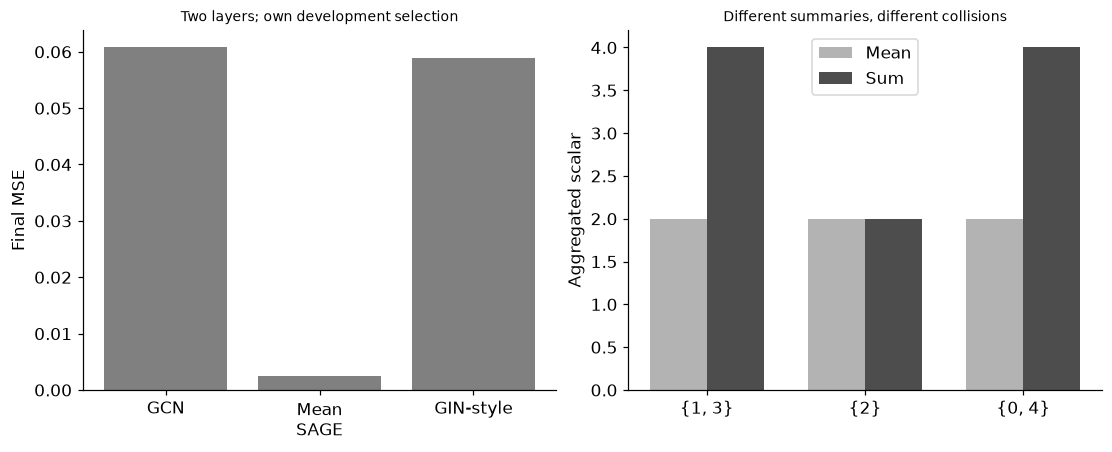

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(3),[r['final_MSE'] for r in rows],color='.5');axes[0].set(xticks=range(3),xticklabels=['GCN','Mean\nSAGE','GIN-style'],ylabel='Final MSE',title='Two layers; own development selection')
xx=np.arange(3);axes[1].bar(xx-.18,[r['mean'] for r in collision],width=.36,color='.7',label='Mean');axes[1].bar(xx+.18,[r['sum'] for r in collision],width=.36,color='.3',label='Sum');axes[1].set(xticks=xx,xticklabels=['{1, 3}','{2}','{0, 4}'],ylabel='Aggregated scalar',title='Different summaries, different collisions');axes[1].legend();plt.show()
assert all(np.isfinite(r['final_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_116','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['edge-feature message trace', 'GCN SAGE and GIN-style learned operators', 'two-hop derivative support', 'permutation and pooling identities', 'disconnected mini-batch contract'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["edge-feature message trace", "GCN SAGE and GIN-style learned operators", "two-hop derivative support", "permutation and pooling identities", "disconnected mini-batch contract"], "elapsed_seconds": 1.763, "example_id": "code_116", "hardware": "Darwin arm64 CPU", "results": {"candidates": [{"best_step": 120, "development_MSE": 0.08187525391690112, "kind": "GCN", "rate": 0.005}, {"best_step": 120, "development_MSE": 0.08312726353943752, "kind": "GCN", "rate": 0.01}, {"best_step": 300, "development_MSE": 0.0025000908947998427, "kind": "Mean SAGE", "rate": 0.005}, {"best_step": 300, "development_MSE": 0.0019628000638798005, "kind": "Mean SAGE", "rate": 0.01}, {"best_step": 110, "development_MSE": 0.08541049964247358, "kind": "GIN-style", "rate": 0.005}, {"best_step": 140, "development_MSE": 0.0790247440849809, "kind": "GIN-style", "rate": 0.01}], "comparisons": [{"best_step": 120, "development_MSE": 0.08187525391690112, "final_MSE": 0.06075